# Conditional KDE baseline

Este notebook organiza el baseline KDE condicional por calendario. El modelo entrena o reutiliza un Autoencoder sobre `X_train`, proyecta los perfiles diarios al espacio latente y ajusta KDEs con fallback jerarquico.

El punto central de esta version es evaluar la sensibilidad de `min_samples` y `bandwidth`. La seleccion de hiperparametros se hace exclusivamente con log-likelihood en validation; test se usa despues para reportar calidad generativa y diagnosticos.

## Setup

Importamos las funciones del modelo y las utilidades compartidas. El notebook puede ejecutarse desde la raiz del proyecto, desde `provincias/` o desde `provincias/notebooks/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from conditional_kde_baseline import run_conditional_kde_baseline
from model_utils import (
    list_generation_plot_paths,
    load_calendar,
    load_result_table,
    load_x_splits,
    plot_metric_by_province,
    plot_month_metrics,
    plot_nrmse_by_province,
    plot_province_hour_heatmap,
    plot_training_history,
    print_split_checks,
    validate_x_splits,
)

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "conditional_kde"
baseline_output_dir = provinces_root / "results" / "conditional_kde_baseline"
pretrained_autoencoder_path = baseline_output_dir / "autoencoder_best.pt"
if not pretrained_autoencoder_path.exists():
    pretrained_autoencoder_path = None

splits_dir, output_dir

(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde'))

## Datos de entrada

Se cargan los perfiles diarios ya escalados y los calendarios ya separados por split. Estos chequeos documentan que el modelo trabaja con matrices de 528 dimensiones y sin NaNs antes de entrenar o evaluar.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


In [3]:
calendar_train = load_calendar(splits_dir, "train")
calendar_val = load_calendar(splits_dir, "val")
calendar_test = load_calendar(splits_dir, "test")

display(calendar_train.head())
display(
    pd.DataFrame(
        {
            "split": ["train", "val", "test"],
            "n_days": [len(calendar_train), len(calendar_val), len(calendar_test)],
            "start": [calendar_train["fecha"].min(), calendar_val["fecha"].min(), calendar_test["fecha"].min()],
            "end": [calendar_train["fecha"].max(), calendar_val["fecha"].max(), calendar_test["fecha"].max()],
        }
    )
)

,fecha,mes,dia_semana,es_feriado
0,2019-01-01,1,1,1
1,2019-01-02,1,2,0
2,2019-01-03,1,3,0
3,2019-01-04,1,4,0
4,2019-01-05,1,5,0


,split,n_days,start,end
0,train,1457,2019-01-01,2023-12-31
1,val,366,2024-01-01,2024-12-31
2,test,485,2025-01-01,2026-04-30


## Entrenamiento y sensibilidad

La celda siguiente invoca el experimento completo. Por defecto queda apagada para no reentrenar ni recalcular escenarios al abrir el notebook. Si faltan resultados, cambiar `RUN_ANALYSIS` a `True`.

La grilla evaluada es `min_samples = [3, 5, 10, 15, 20]` y `bandwidth = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]`.

In [4]:
RUN_ANALYSIS = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    pretrained_autoencoder_path=pretrained_autoencoder_path,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    patience=25,
    min_delta=1e-5,
    min_samples=20,
    min_samples_grid=[3, 5, 10, 15, 20],
    bandwidths=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
)

if RUN_ANALYSIS:
    output_paths = run_conditional_kde_baseline(config)
    display(output_paths)
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_kde


In [5]:
required_files = [
    output_dir / "config.json",
    output_dir / "autoencoder_history.csv",
    output_dir / "kde_min_samples_bandwidth_sensitivity.csv",
    output_dir / "test_fallback_usage.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_month.csv",
    output_dir / "metrics_by_province.csv",
    output_dir / "coverage_by_province_hour.csv",
    output_dir / "rmse_by_province_hour.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Faltan resultados guardados. Cambiar RUN_ANALYSIS a True y volver a ejecutar. "
        f"Archivos faltantes: {missing_files}"
    )

## Configuracion y Autoencoder

El Autoencoder define el espacio latente sobre el cual se ajustan los KDEs. La reconstruction loss se reporta en escala normalizada; las metricas generativas posteriores se reportan en MWh.

,value
bandwidths,"[0.5, 0.75, 1.0, 1.25, 1.5, 2.0]"
batch_size,64
best_bandwidth,1.5
best_min_samples,20
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,cpu
epochs,200
hidden_dim,256
latent_dim,16
learning_rate,0.001


,split,reconstruction_mse_scaled
0,train,0.046317
1,val,0.097052
2,test,0.146215


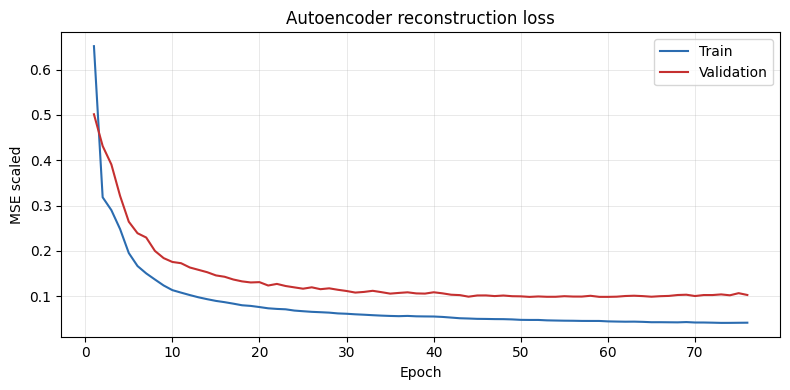

In [6]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

history = load_result_table(output_dir, "autoencoder_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")

display(pd.Series(saved_config, name="value").to_frame())
display(reconstruction_metrics)
plot_training_history(
    history,
    train_column="train_loss",
    val_column="val_loss",
    title="Autoencoder reconstruction loss",
    ylabel="MSE scaled",
)

## Sensibilidad de min_samples y bandwidth

La mejor configuracion se elige por log-likelihood promedio en validation. Las metricas de test se agregan despues para entender el trade-off, pero no participan en la seleccion.

In [7]:
sensitivity = load_result_table(output_dir, "kde_min_samples_bandwidth_sensitivity.csv")
best_config = sensitivity.sort_values("val_log_likelihood", ascending=False).iloc[0]

display(sensitivity.sort_values("val_log_likelihood", ascending=False))
display(best_config.to_frame("best_value"))

,min_samples,bandwidth,val_log_likelihood,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,n_full,n_month_weekday,n_month,n_global
0,20,1.50,-33.287754,0.871774,376.864675,253.123978,0.009581,0,0,485,0
1,3,2.00,-33.823779,0.891229,369.024100,222.598007,0.006517,470,15,0,0
2,10,2.00,-33.832160,0.892869,370.023251,222.881912,0.006448,462,23,0,0
3,5,2.00,-33.832160,0.892869,370.023251,222.881912,0.006448,462,23,0,0
4,15,2.00,-33.843279,0.892131,370.685953,225.198257,0.006757,422,63,0,0
5,20,2.00,-33.846310,0.894037,404.342024,253.101471,0.008879,0,0,485,0
6,3,1.50,-34.014320,0.866842,335.889233,222.384979,0.006316,470,15,0,0
7,10,1.50,-34.019354,0.869096,337.122004,222.517044,0.006191,462,23,0,0
8,5,1.50,-34.019354,0.869096,337.122004,222.517044,0.006191,462,23,0,0
9,15,1.50,-34.030699,0.868354,337.929048,225.004944,0.006750,422,63,0,0


,best_value
min_samples,20.000000
bandwidth,1.500000
val_log_likelihood,-33.287754
test_coverage,0.871774
test_sharpness,376.864675
test_rmse_mean_profile,253.123978
test_mmd,0.009581
n_full,0.000000
n_month_weekday,0.000000
n_month,485.000000


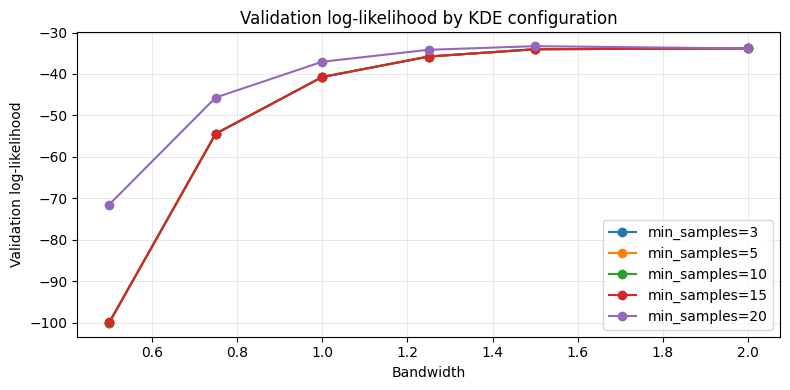

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for min_samples, group in sensitivity.groupby("min_samples"):
    ordered = group.sort_values("bandwidth")
    ax.plot(ordered["bandwidth"], ordered["val_log_likelihood"], marker="o", label=f"min_samples={min_samples}")
ax.set_title("Validation log-likelihood by KDE configuration")
ax.set_xlabel("Bandwidth")
ax.set_ylabel("Validation log-likelihood")
ax.grid(linewidth=0.4, alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

La tabla de fallback indica que condicionamiento efectivamente uso el modelo en test. Si predominan los grupos `full` o `month_weekday`, bajar `min_samples` permitio incorporar mas informacion de calendario. Si predomina `month`, los grupos mas especificos tenian pocas muestras y el fallback mensual resulto mas estable. Por eso no conviene afirmar que el KDE esta condicionado por todas las variables calendario si la evaluacion muestra que el fallback cae mayormente al mes.

In [9]:
fallback_usage = load_result_table(output_dir, "test_fallback_usage.csv")
fallback_counts = fallback_usage["fallback_level"].value_counts().rename_axis("fallback_level").to_frame("n_days")
display(fallback_counts)

dominant_fallback = fallback_counts["n_days"].idxmax()
if dominant_fallback in ["full", "month_weekday"]:
    print("La configuracion seleccionada usa grupos calendario mas especificos en una parte relevante de test.")
else:
    print("La configuracion seleccionada sigue usando mayormente fallback mensual; el condicionamiento efectivo es principalmente por mes.")

,n_days
fallback_level,
month,485


La configuracion seleccionada sigue usando mayormente fallback mensual; el condicionamiento efectivo es principalmente por mes.


## Evaluacion overall

Coverage y sharpness resumen la banda P5-P95 generada. RMSE compara el perfil real contra el perfil medio generado. MMD compara la distribucion de perfiles reales contra la distribucion sintetica.

In [10]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
display(overall_metrics.T.rename(columns={0: "value"}))

row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

,value
coverage_p5_p95,0.871774
sharpness_p5_p95_mwh,376.864675
mean_profile_rmse_mwh,253.123978
mmd_rbf,0.009581
n_days,485.000000
n_scenarios_per_day,500.000000


Coverage P5-P95: 0.872
Sharpness promedio P5-P95: 376.86 MWh
RMSE del perfil medio: 253.12 MWh
MMD RBF: 0.009581


## Evaluacion por mes

La evaluacion mensual muestra si el condicionamiento por calendario ayuda a capturar estacionalidad. Meses con demanda extrema pueden tener mayor error o menor coverage si la variabilidad real es mas amplia que la banda generada.

,mes,coverage,sharpness,rmse_mean_profile,n_days
0,1,0.904326,453.493206,300.069672,62
1,2,0.724871,439.127098,311.047821,56
2,3,0.882331,488.381097,289.273132,62
3,4,0.896275,272.378656,148.235687,60
4,5,0.912085,311.380458,258.114807,31
5,6,0.907765,364.145550,234.296860,30
6,7,0.837915,337.530776,253.844513,31
7,8,0.918255,310.488969,209.528961,31
8,9,0.866856,297.684871,189.452530,30
9,10,0.908602,303.486899,140.266037,31


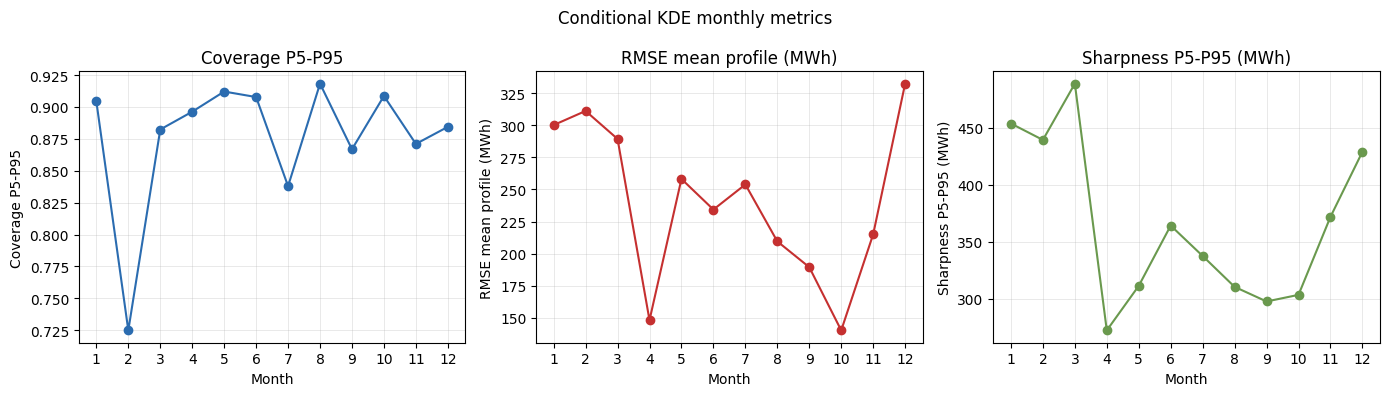

Menor RMSE mensual: mes 10, RMSE=140.27 MWh
Mayor RMSE mensual: mes 12, RMSE=332.29 MWh


In [11]:
metrics_by_month = load_result_table(output_dir, "metrics_by_month.csv")
display(metrics_by_month)
plot_month_metrics(metrics_by_month, "Conditional KDE monthly metrics")

best_month = metrics_by_month.sort_values("rmse_mean_profile").iloc[0]
worst_month = metrics_by_month.sort_values("rmse_mean_profile", ascending=False).iloc[0]
print(f"Menor RMSE mensual: mes {int(best_month['mes'])}, RMSE={best_month['rmse_mean_profile']:.2f} MWh")
print(f"Mayor RMSE mensual: mes {int(worst_month['mes'])}, RMSE={worst_month['rmse_mean_profile']:.2f} MWh")

## NRMSE por provincia

El RMSE absoluto crece con la escala de demanda. El NRMSE divide el error por la demanda media provincial y permite detectar provincias chicas con errores relativos altos aunque su error en MWh parezca bajo.

,province,rmse,mean_profile_rmse_mwh,mean_demand,mean_demand_mwh,nrmse,coverage,coverage_p5_p95,sharpness,sharpness_p5_p95_mwh,mmd_rbf
20,sgo_del_estero,74.651115,74.651115,241.469025,241.469025,0.309154,0.856873,0.856873,175.470457,175.470457,0.037498
2,chaco,104.566498,104.566498,401.316223,401.316223,0.260559,0.874055,0.874055,285.476740,285.476740,0.020032
7,formosa,44.938393,44.938393,184.996826,184.996826,0.242914,0.874055,0.874055,132.186458,132.186458,0.020159
5,corrientes,80.491882,80.491882,375.334198,375.334198,0.214454,0.878093,0.878093,216.685092,216.685092,0.017346
21,tucuman,82.807968,82.807968,392.474487,392.474487,0.210989,0.900859,0.900859,227.158945,227.158945,0.019126
16,san_juan,55.475441,55.475441,285.251984,285.251984,0.194479,0.909966,0.909966,159.413168,159.413168,0.013467
1,catamarca,31.071754,31.071754,164.645828,164.645828,0.188719,0.858162,0.858162,79.780640,79.780640,0.052765
10,la_rioja,34.504391,34.504391,186.800217,186.800217,0.184713,0.891409,0.891409,101.092869,101.092869,0.011833


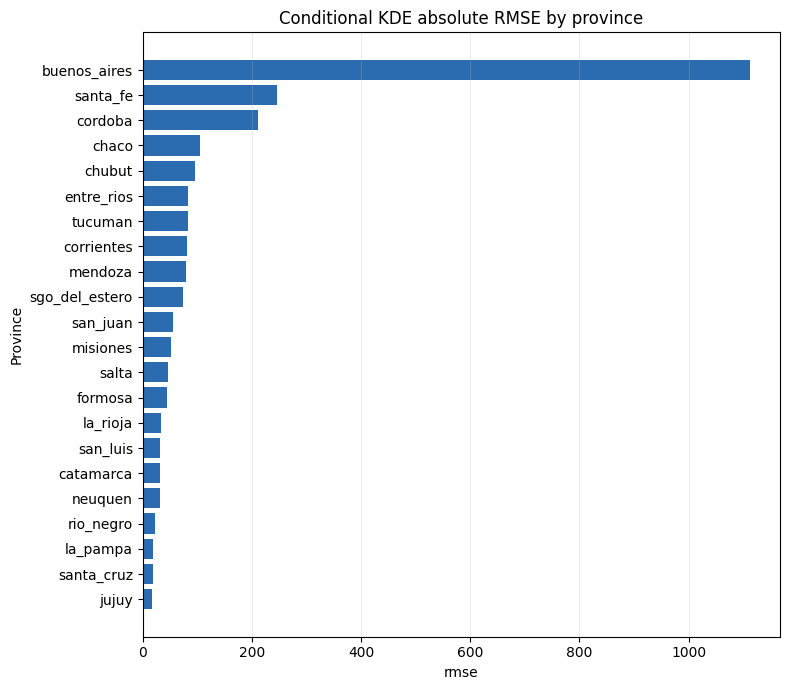

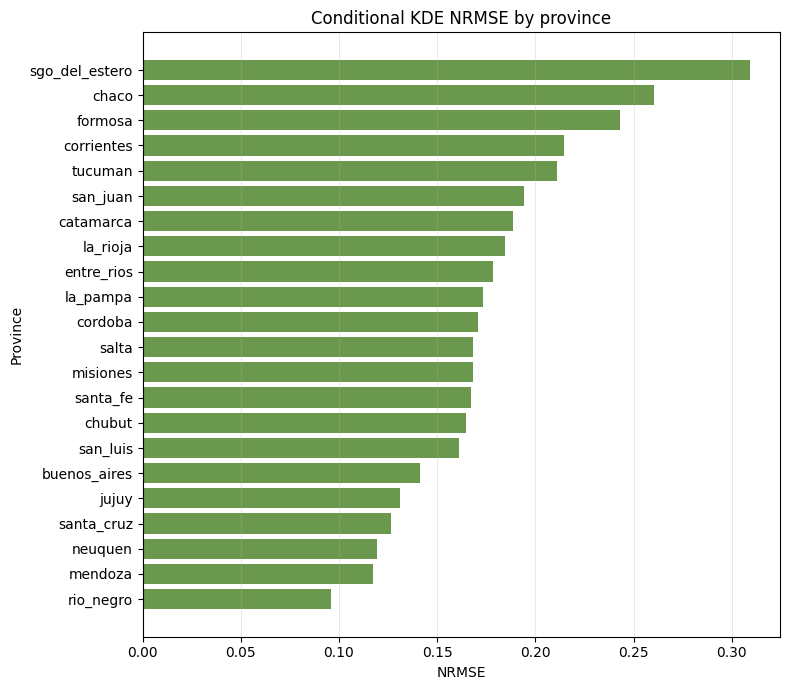

In [12]:
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")
display(province_metrics.sort_values("nrmse", ascending=False).head(8))
plot_metric_by_province(province_metrics, metric="rmse", title="Conditional KDE absolute RMSE by province")
plot_nrmse_by_province(province_metrics, title="Conditional KDE NRMSE by province")

if "santa_cruz" in province_metrics.sort_values("nrmse", ascending=False).head(5)["province"].to_list():
    print("Santa Cruz aparece entre las provincias con NRMSE mas alto y conviene revisarla como caso problematico relativo.")

## Heatmaps provincia-hora

Los heatmaps permiten ubicar errores por provincia y por hora. Un coverage bajo concentrado en algunas horas sugiere problemas para representar picos o valles diarios; RMSE alto en provincias grandes puede responder a escala, mientras que RMSE moderado con NRMSE alto puede revelar problemas relativos en provincias chicas.

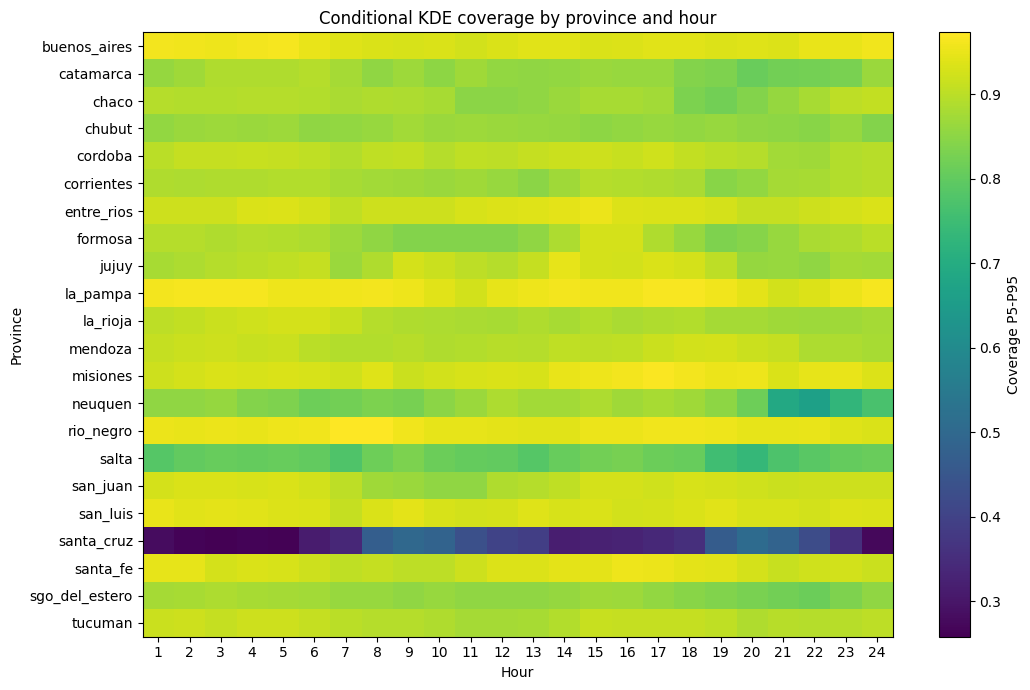

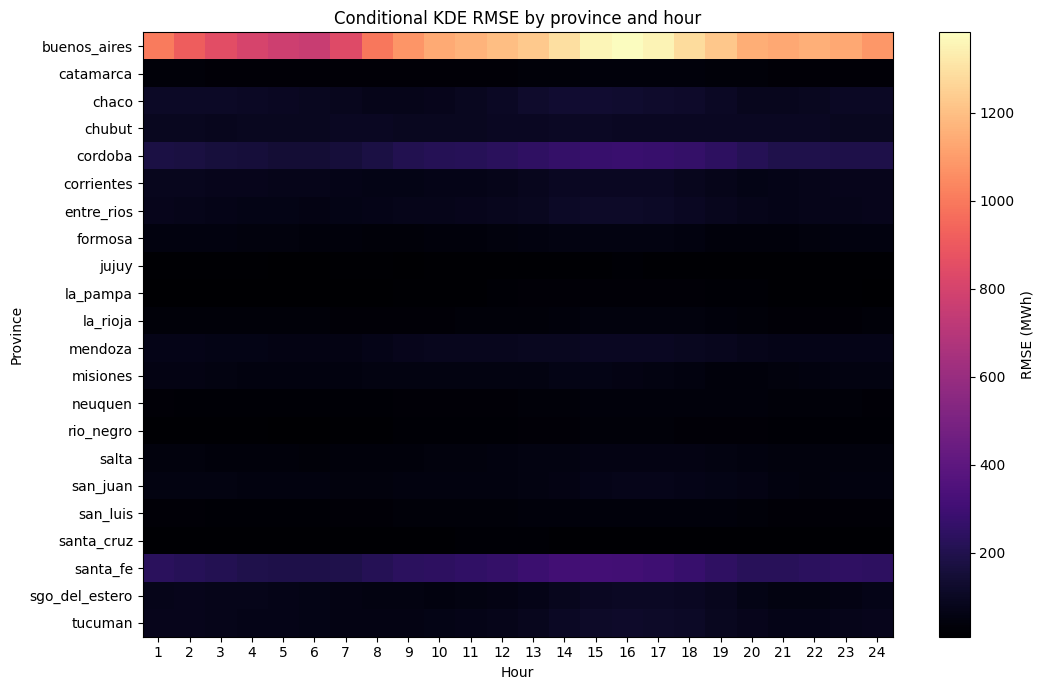

In [13]:
coverage_by_hour = pd.read_csv(output_dir / "coverage_by_province_hour.csv", index_col=0)
rmse_by_hour = pd.read_csv(output_dir / "rmse_by_province_hour.csv", index_col=0)

plot_province_hour_heatmap(
    coverage_by_hour,
    title="Conditional KDE coverage by province and hour",
    colorbar_label="Coverage P5-P95",
    cmap="viridis",
)
plot_province_hour_heatmap(
    rmse_by_hour,
    title="Conditional KDE RMSE by province and hour",
    colorbar_label="RMSE (MWh)",
    cmap="magma",
)

In [14]:
coverage_hour_mean = coverage_by_hour.mean(axis=0)
rmse_hour_mean = rmse_by_hour.mean(axis=0)
print(f"Hora con menor coverage promedio: {coverage_hour_mean.idxmin()}")
print(f"Hora con mayor RMSE promedio: {rmse_hour_mean.idxmax()}")
display(rmse_by_hour.mean(axis=1).sort_values(ascending=False).head())

Hora con menor coverage promedio: hour_22
Hora con mayor RMSE promedio: hour_16


buenos_aires    1096.119451
santa_fe         243.233278
cordoba          207.717541
chaco            103.101752
chubut            95.520594
dtype: float64

## Perfiles reales vs generados

Los graficos guardados comparan el perfil horario agregado del sistema contra la media generada y la banda P5-P95 para dias representativos de test.

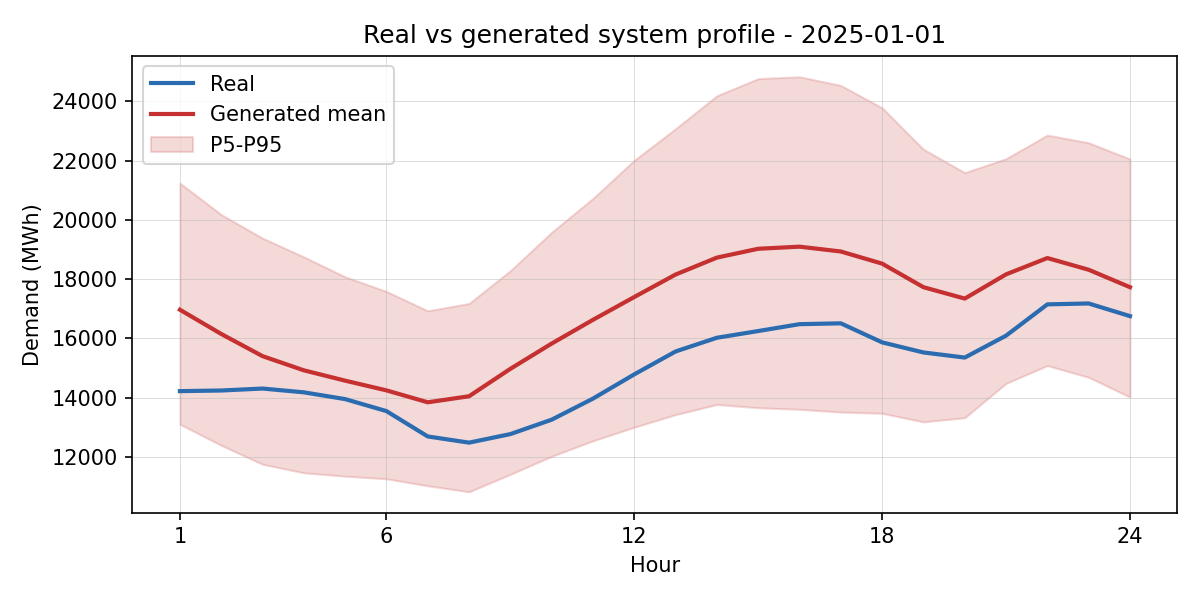

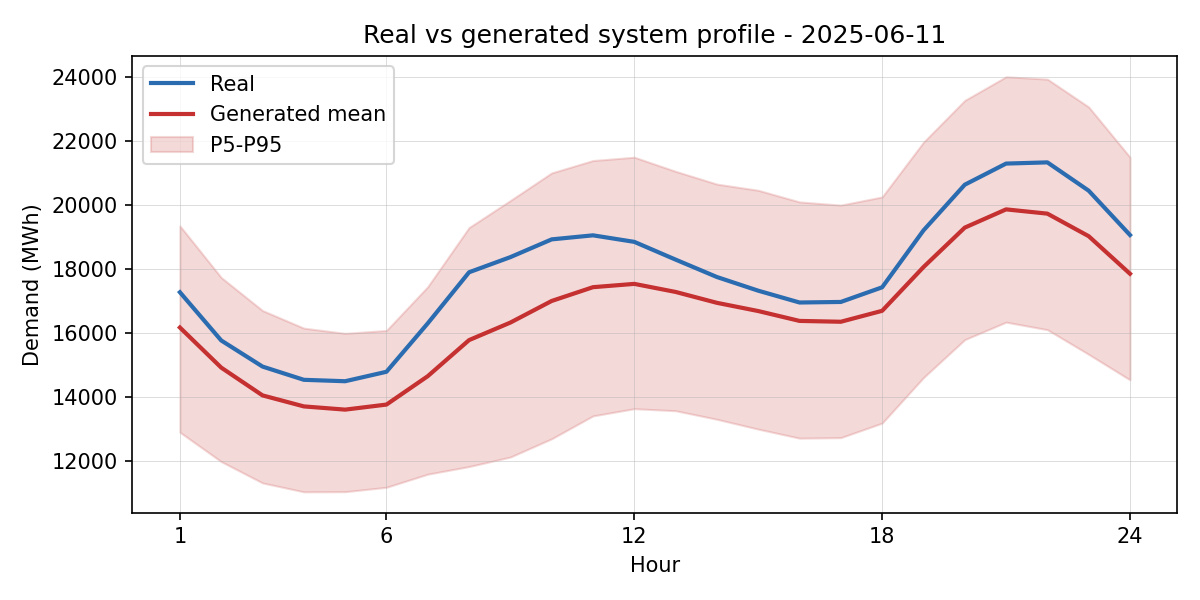

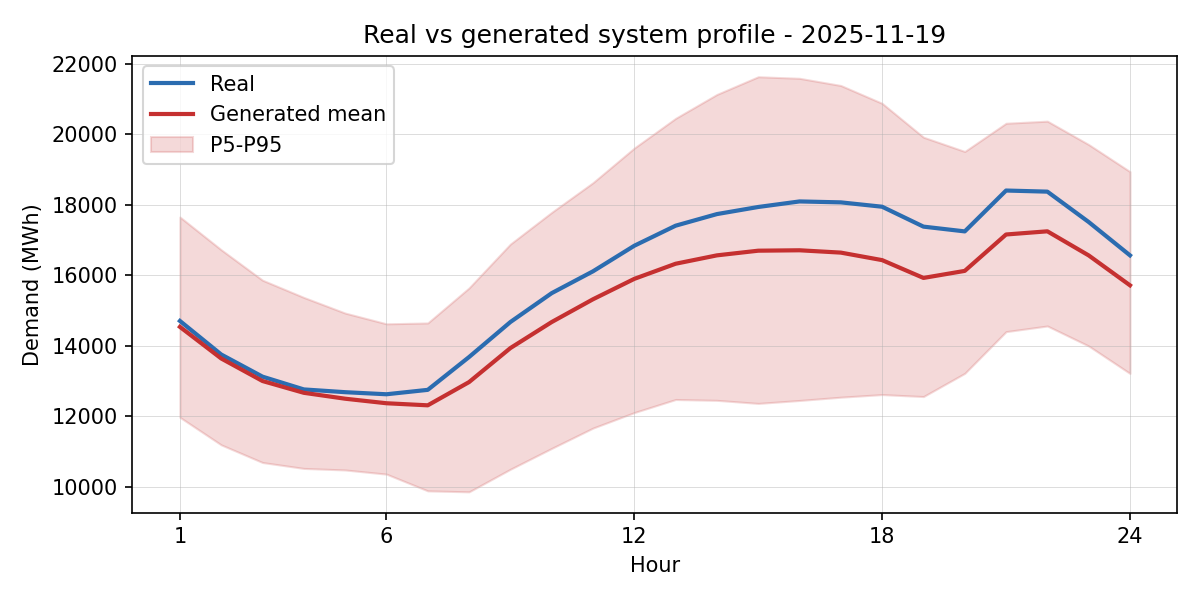

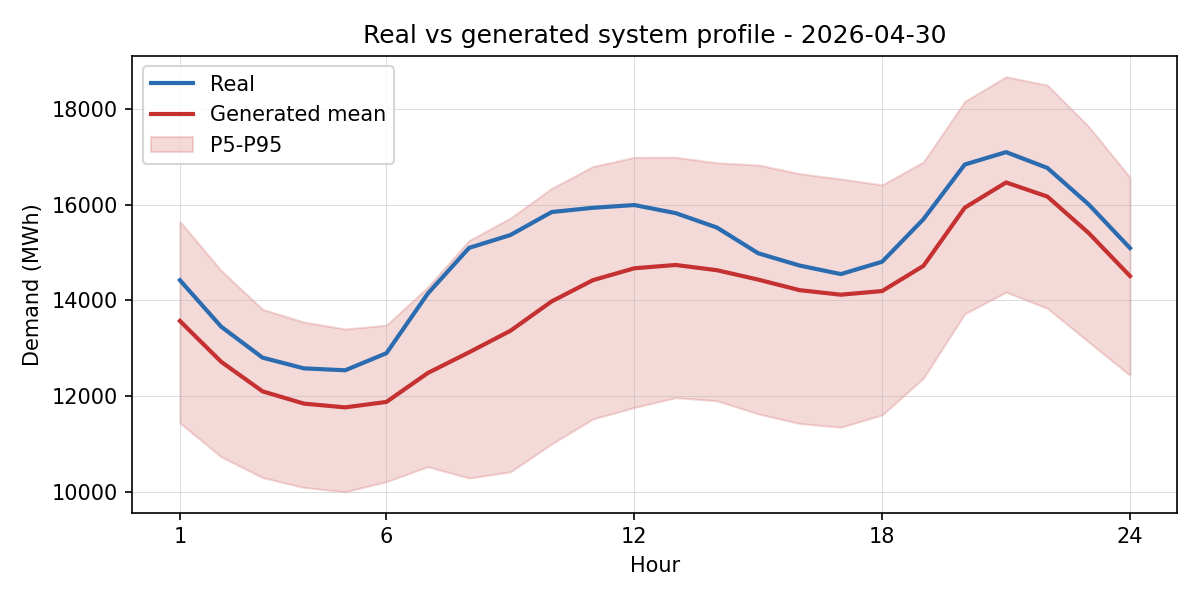

In [15]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

El KDE condicional mejora sustancialmente al VAE en coverage, RMSE y MMD. Esto sugiere que la estacionalidad calendaria contiene información relevante para la generación de perfiles diarios. Sin embargo, la mejor configuración seleccionada por validación utiliza fallback mensual en todos los días de test, por lo que el modelo debe interpretarse como un KDE mensual en espacio latente. Esta limitación refuerza la necesidad de un modelo condicional más flexible, como el CVAE, capaz de incorporar clima y calendario sin depender de grupos discretos con pocas muestras.